# Moirai-2.0 Zero-Shot Baseline

## Overview
- **Input**: `data/processed/v2/features_train.csv`, `data/processed/v2/features_test.csv`
- **Output**: `data/results/moirai_results.csv`, `data/results/moirai_summary.csv`

## Strategy
- GluonTS PandasDataset + rolling 1-step sliding window
- Predict Close price (median quantile) for every test day
- Convert to log return: `pred_ret = ln(pred_close / actual_close_{T-1})`
- Evaluate with MAE, RMSE, DA, IC + per-regime breakdown

**Model**: Salesforce/moirai-2.0-R-small  
**Install**: `pip install uni2ts gluonts`  
**Zero-shot**: No fine-tuning, weights frozen.

In [22]:
import os
os.environ["KMP_DUPLICATE_LIB_OK"] = "TRUE"

import sys
import warnings
import numpy as np
import pandas as pd
from pathlib import Path

warnings.filterwarnings("ignore")
if sys.stdout.encoding and sys.stdout.encoding.lower() != "utf-8":
    sys.stdout.reconfigure(encoding="utf-8", errors="replace")

In [23]:
# ========== SETUP PATHS & CONFIG ==========
ROOT_DIR   = Path.cwd().parent.parent
TRAIN_PATH = ROOT_DIR / "data" / "processed" / "v2" / "features_train.csv"
TEST_PATH  = ROOT_DIR / "data" / "processed" / "v2" / "features_test.csv"
OUT_DIR    = ROOT_DIR / "data" / "results"
OUT_DIR.mkdir(parents=True, exist_ok=True)

MODEL_NAME      = "Salesforce/moirai-2.0-R-small"
CONTEXT_LENGTH  = 128   # ngày lịch sử mỗi bước
PREDICTION_LENGTH = 1   # 1-step ahead

print(f"ROOT_DIR: {ROOT_DIR}")
print(f"TRAIN_PATH: {TRAIN_PATH}")
print(f"TEST_PATH: {TEST_PATH}")
print(f"OUT_DIR: {OUT_DIR}")

ROOT_DIR: d:\fm-forecasting
TRAIN_PATH: d:\fm-forecasting\data\processed\v2\features_train.csv
TEST_PATH: d:\fm-forecasting\data\processed\v2\features_test.csv
OUT_DIR: d:\fm-forecasting\data\results


In [24]:
# ========== HELPER FUNCTION: EVALUATION METRICS ==========
def eval_metrics(y_true: np.ndarray, y_pred: np.ndarray) -> dict:
    """Calculate MAE, RMSE, Directional Accuracy (DA), Information Coefficient (IC)"""
    mae  = np.mean(np.abs(y_true - y_pred))
    rmse = np.sqrt(np.mean((y_true - y_pred) ** 2))
    da   = np.mean(np.sign(y_true) == np.sign(y_pred))
    ic   = np.corrcoef(y_true, y_pred)[0, 1] if np.std(y_pred) > 0 else 0.0
    return {"MAE": mae, "RMSE": rmse, "DA": da, "IC": ic}

In [25]:
# ========== LOAD DATA ==========
print("Loading training and test data...")
train = pd.read_csv(TRAIN_PATH, parse_dates=["Date"])
test  = pd.read_csv(TEST_PATH,  parse_dates=["Date"])

tickers = sorted(train["ticker"].unique())
print(f"Tickers ({len(tickers)}): {tickers}")
print(f"Train shape: {train.shape}")
print(f"Test shape: {test.shape}")

Loading training and test data...
Tickers (15): ['ACB', 'BVH', 'CTG', 'FPT', 'GAS', 'HPG', 'KDH', 'MBB', 'MSN', 'PDR', 'SSI', 'STB', 'VCB', 'VIC', 'VNM']
Train shape: (34917, 21)
Test shape: (13140, 21)


In [26]:
# ========== IMPORT GLUONTS & MOIRAI ==========
try:
    from uni2ts.model.moirai2 import Moirai2Forecast, Moirai2Module
    from gluonts.dataset.pandas import PandasDataset
    from gluonts.dataset.split import split
    print("✓ uni2ts và gluonts imported successfully")
except ImportError as e:
    print(f"ERROR: {e}")
    print("Run: pip install uni2ts gluonts")
    raise

✓ uni2ts và gluonts imported successfully


In [27]:
# ========== PREPARE PANEL DATA: RESAMPLE BUSINESS DAYS ==========
print("\nPreparing panel data (resample to Business Days)...")
df_all = pd.concat([train, test], ignore_index=True)
dfs = []
for ticker_id, group in df_all.groupby("ticker"):
    g = group.set_index("Date").resample("B").ffill()
    g["ticker"] = ticker_id
    dfs.append(g.reset_index())

df_ticker = pd.concat(dfs, ignore_index=True)[["ticker", "Date", "Close"]]
print(f"Panel after resample: {len(df_ticker)} rows | {df_ticker['ticker'].nunique()} tickers")
print(df_ticker.head())


Preparing panel data (resample to Business Days)...
Panel after resample: 50205 rows | 15 tickers
  ticker       Date  Close
0    ACB 2013-03-04  2.298
1    ACB 2013-03-05  2.284
2    ACB 2013-03-06  2.312
3    ACB 2013-03-07  2.298
4    ACB 2013-03-08  2.312


In [28]:
# ========== CREATE GLUONTS DATASET & SPLIT ==========
print("\nCreating GluonTS dataset...")
ds = PandasDataset.from_long_dataframe(
    df_ticker,
    target="Close",
    item_id="ticker",
    timestamp="Date",
    freq="B",
)
print(f"Dataset created with {len(ds)} time series")

# FIX: tinh n_test tu df_ticker resampled (khong tu file test goc)
# Vi resample 'B' co the them extra business days -> split bi lech voi test goc
CUTOFF = pd.Timestamp("2022-07-01")
n_test = int(df_ticker[df_ticker["Date"] >= CUTOFF].groupby("ticker")["Date"].nunique().max())
pred_len = int(PREDICTION_LENGTH)
print(f"Resampled test days: {n_test}  (original: {int(test.groupby('ticker')['Date'].nunique().max())})")

print("\nSplitting into train and test templates...")
train_dataset, test_template = split(ds, offset=-n_test)

print("Generating rolling window instances...")
test_data = test_template.generate_instances(
    prediction_length=pred_len,
    windows=n_test,
    distance=pred_len,
)
print("✓ Rolling windows ready")


Creating GluonTS dataset...
Dataset created with 15 time series
Resampled test days: 913  (original: 876)

Splitting into train and test templates...
Generating rolling window instances...
✓ Rolling windows ready


In [29]:
# ========== LOAD MOIRAI-2.0 MODEL ==========
print(f"\nLoading {MODEL_NAME}...")
model = Moirai2Forecast(
    module=Moirai2Module.from_pretrained(MODEL_NAME),
    prediction_length=PREDICTION_LENGTH,
    context_length=CONTEXT_LENGTH,
    target_dim=1,
    feat_dynamic_real_dim=0,
    past_feat_dynamic_real_dim=0,
)
predictor = model.create_predictor(batch_size=64)
print("✓ Model loaded successfully")


Loading Salesforce/moirai-2.0-R-small...


✓ Model loaded successfully


In [30]:
# ========== ZERO-SHOT INFERENCE ==========
print("\nRunning zero-shot inference...")
forecast_it    = predictor.predict(test_data.input)
forecasts_list = list(forecast_it)
print(f"✓ Total forecasts generated: {len(forecasts_list)}")


Running zero-shot inference...
✓ Total forecasts generated: 13695


In [31]:
# ========== PARSE PREDICTIONS: PRED CLOSE -> PRED RETURN ==========
print("\nParsing predictions and computing log returns...")
pred_rows = []
for forecast in forecasts_list:
    ticker     = forecast.item_id
    pred_date  = forecast.start_date.to_timestamp()
    pred_close = float(forecast.quantile(0.5)[0])

    # Close ngày liền trước pred_date
    prev_close_ser = df_ticker[
        (df_ticker["ticker"] == ticker) &
        (df_ticker["Date"] < pred_date)
    ]["Close"]

    if len(prev_close_ser) > 0 and prev_close_ser.iloc[-1] > 0 and pred_close > 0:
        pred_ret = np.log(pred_close / prev_close_ser.iloc[-1])
    else:
        pred_ret = 0.0

    pred_rows.append({
        "Date"      : pred_date,
        "ticker"    : ticker,
        "pred_close": pred_close,
        "pred"      : pred_ret,
    })

df_preds = pd.DataFrame(pred_rows)
print(f"✓ Predictions parsed: {len(df_preds)} rows")
print(df_preds.head())


Parsing predictions and computing log returns...
✓ Predictions parsed: 13695 rows
        Date ticker  pred_close      pred
0 2022-07-01    ACB   14.036398 -0.002391
1 2022-07-04    ACB   14.080854 -0.001288
2 2022-07-05    ACB   14.221008  0.000352
3 2022-07-06    ACB   14.355231  0.001550
4 2022-07-07    ACB   14.194942  0.000560


In [32]:
# ========== MERGE WITH ACTUAL TARGET & REGIME ==========
print("\nMerging predictions with actual targets and regimes...")
test_meta = test[["Date", "ticker", "target", "regime_hmm"]].copy()
results = test_meta.merge(df_preds[["Date", "ticker", "pred"]], on=["Date", "ticker"], how="left")
results["pred"] = results["pred"].fillna(0.0)

results.to_csv(OUT_DIR / "moirai_results.csv", index=False)
print(f"✓ Saved: {OUT_DIR / 'moirai_results.csv'}")
print(results.head())


Merging predictions with actual targets and regimes...
✓ Saved: d:\fm-forecasting\data\results\moirai_results.csv
        Date ticker    target regime_hmm      pred
0 2022-07-01    ACB  0.008264       Bear -0.002391
1 2022-07-04    ACB  0.008196       Bear -0.001288
2 2022-07-05    ACB -0.010239       Bear  0.000352
3 2022-07-06    ACB -0.002117       Bear  0.001550
4 2022-07-07    ACB -0.006164       Bear  0.000560


In [33]:
# ========== COMPUTE SUMMARY METRICS ==========
print("\n" + "=" * 60)
print("MOIRAI-2.0 — OVERALL METRICS")
print("=" * 60)

summary_rows = []
for ticker in tickers:
    sub = results[results["ticker"] == ticker]
    m   = eval_metrics(sub["target"].values, sub["pred"].values)
    print(f"[{ticker}] MAE={m['MAE']:.6f} | RMSE={m['RMSE']:.6f} | DA={m['DA']:.3f} | IC={m['IC']:.4f}")
    summary_rows.append({"ticker": ticker, **m})

summary = pd.DataFrame(summary_rows)
overall = eval_metrics(results["target"].values, results["pred"].values)
summary.loc[len(summary)] = {"ticker": "OVERALL", **overall}
summary.to_csv(OUT_DIR / "moirai_summary.csv", index=False)

print("\n" + summary.round(6).to_string(index=False))
print(f"\n✓ Saved: {OUT_DIR / 'moirai_summary.csv'}")


MOIRAI-2.0 — OVERALL METRICS
[ACB] MAE=0.010711 | RMSE=0.016283 | DA=0.412 | IC=-0.1136
[BVH] MAE=0.013086 | RMSE=0.019124 | DA=0.444 | IC=-0.0285
[CTG] MAE=0.013358 | RMSE=0.019323 | DA=0.499 | IC=-0.0322
[FPT] MAE=0.011702 | RMSE=0.016482 | DA=0.499 | IC=0.0707
[GAS] MAE=0.010833 | RMSE=0.016271 | DA=0.449 | IC=-0.0963
[HPG] MAE=0.014838 | RMSE=0.021376 | DA=0.470 | IC=-0.0268
[KDH] MAE=0.015646 | RMSE=0.022947 | DA=0.461 | IC=0.0138
[MBB] MAE=0.012717 | RMSE=0.018594 | DA=0.469 | IC=-0.0179
[MSN] MAE=0.015245 | RMSE=0.021340 | DA=0.482 | IC=-0.0176
[PDR] MAE=0.021562 | RMSE=0.030371 | DA=0.477 | IC=0.1548
[SSI] MAE=0.017964 | RMSE=0.025191 | DA=0.457 | IC=0.0296
[STB] MAE=0.016222 | RMSE=0.023027 | DA=0.495 | IC=-0.0329
[VCB] MAE=0.009950 | RMSE=0.014561 | DA=0.441 | IC=-0.0092
[VIC] MAE=0.015868 | RMSE=0.024172 | DA=0.467 | IC=0.0811
[VNM] MAE=0.009971 | RMSE=0.013980 | DA=0.465 | IC=0.0178

 ticker      MAE     RMSE       DA        IC
    ACB 0.010711 0.016283 0.412100 -0.113556


In [34]:
# ========== PER-REGIME BREAKDOWN ==========
print("\n" + "=" * 60)
print("PER-REGIME BREAKDOWN")
print("=" * 60)

for regime in ["Bull", "Sideways", "Bear"]:
    mask = results["regime_hmm"] == regime
    if mask.sum() == 0:
        print(f"{regime:10s}: (no data)")
        continue
    m = eval_metrics(results.loc[mask, "target"].values, results.loc[mask, "pred"].values)
    print(f"{regime:10s}: MAE={m['MAE']:.6f} | RMSE={m['RMSE']:.6f} | DA={m['DA']:.3f} | IC={m['IC']:.4f} | n={mask.sum()}")


PER-REGIME BREAKDOWN
Bull      : MAE=0.015041 | RMSE=0.021269 | DA=0.449 | IC=0.0141 | n=3495
Sideways  : MAE=0.010611 | RMSE=0.015444 | DA=0.468 | IC=0.0051 | n=6870
Bear      : MAE=0.020975 | RMSE=0.029351 | DA=0.482 | IC=0.0726 | n=2775


In [35]:
# ========== FINAL SUMMARY ==========
print("\n" + "=" * 60)
print("PROCESS COMPLETED")
print("=" * 60)
print(f"Results saved to:")
print(f"  - {OUT_DIR / 'moirai_results.csv'}")
print(f"  - {OUT_DIR / 'moirai_summary.csv'}")
print(f"\nTotal predictions: {len(df_preds)} rows")
print(f"Tickers: {len(tickers)}")
print(f"Model: {MODEL_NAME}")
print(f"Context Length: {CONTEXT_LENGTH} days")
print(f"Prediction Length: {PREDICTION_LENGTH} day(s)")


PROCESS COMPLETED
Results saved to:
  - d:\fm-forecasting\data\results\moirai_results.csv
  - d:\fm-forecasting\data\results\moirai_summary.csv

Total predictions: 13695 rows
Tickers: 15
Model: Salesforce/moirai-2.0-R-small
Context Length: 128 days
Prediction Length: 1 day(s)


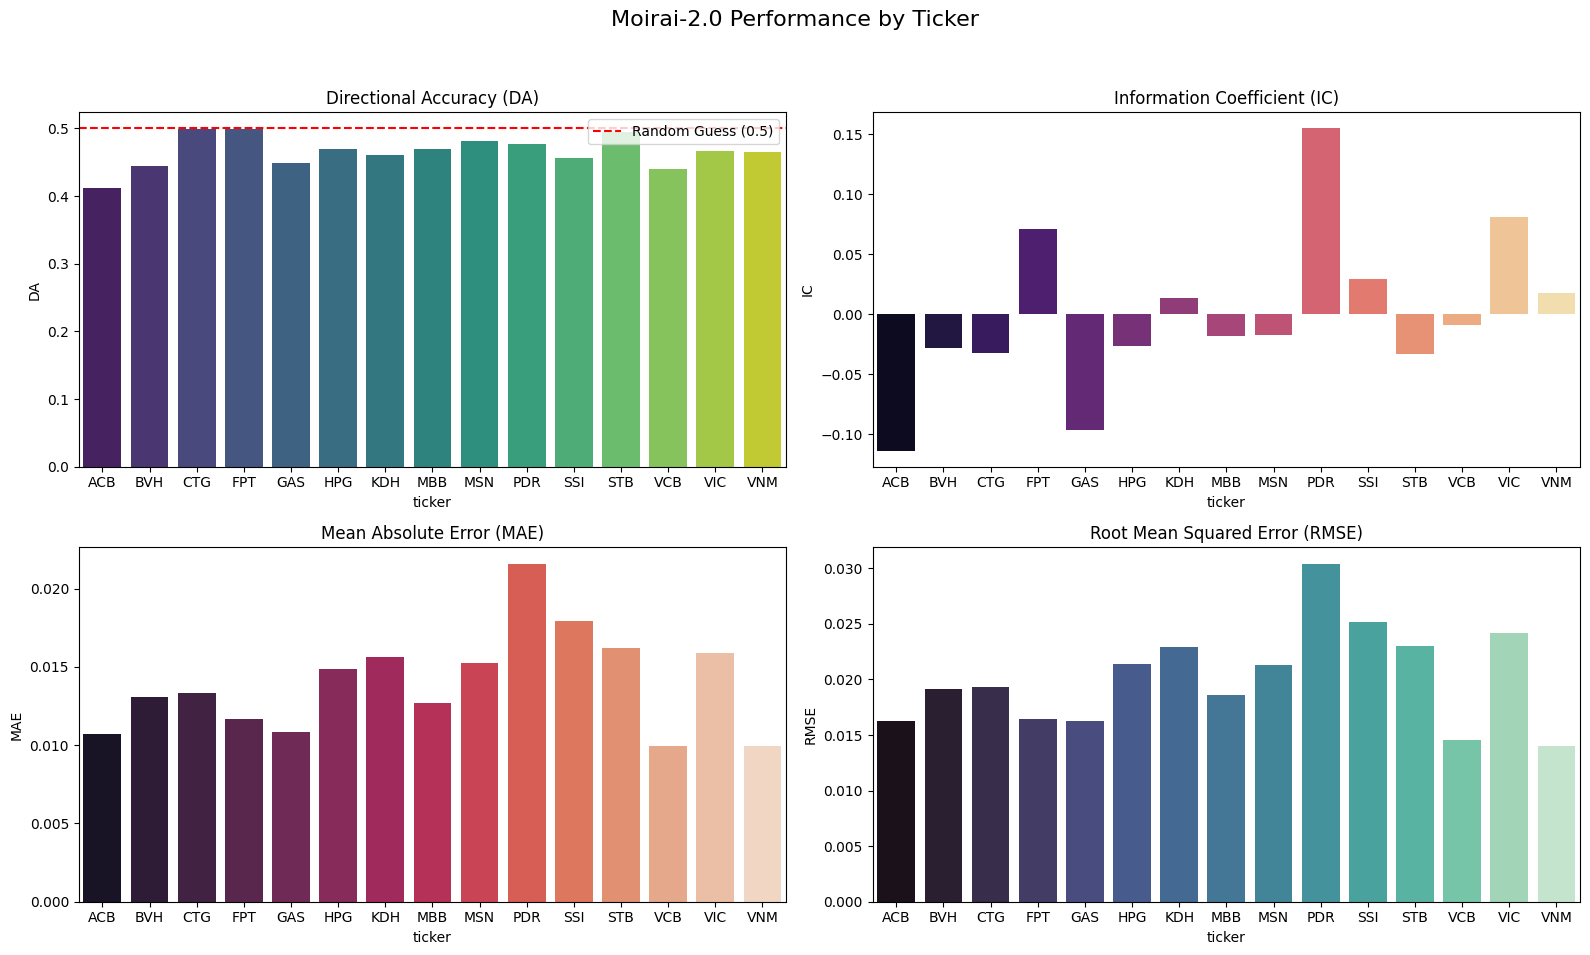

In [36]:
import matplotlib.pyplot as plt
import seaborn as sns

# Chuẩn bị dữ liệu (loại bỏ dòng OVERALL để vẽ biểu đồ các ticker)
df_plot_tickers = summary[summary['ticker'] != 'OVERALL']

fig, axes = plt.subplots(2, 2, figsize=(16, 10))
fig.suptitle('Moirai-2.0 Performance by Ticker', fontsize=16)

# 1. Directional Accuracy
sns.barplot(data=df_plot_tickers, x='ticker', y='DA', ax=axes[0,0], palette='viridis')
axes[0,0].axhline(0.5, color='red', linestyle='--', label='Random Guess (0.5)')
axes[0,0].set_title('Directional Accuracy (DA)')
axes[0,0].legend()

# 2. Information Coefficient
sns.barplot(data=df_plot_tickers, x='ticker', y='IC', ax=axes[0,1], palette='magma')
axes[0,1].set_title('Information Coefficient (IC)')

# 3. MAE
sns.barplot(data=df_plot_tickers, x='ticker', y='MAE', ax=axes[1,0], palette='rocket')
axes[1,0].set_title('Mean Absolute Error (MAE)')

# 4. RMSE
sns.barplot(data=df_plot_tickers, x='ticker', y='RMSE', ax=axes[1,1], palette='mako')
axes[1,1].set_title('Root Mean Squared Error (RMSE)')

plt.tight_layout(rect=[0, 0.03, 1, 0.95])
plt.show()

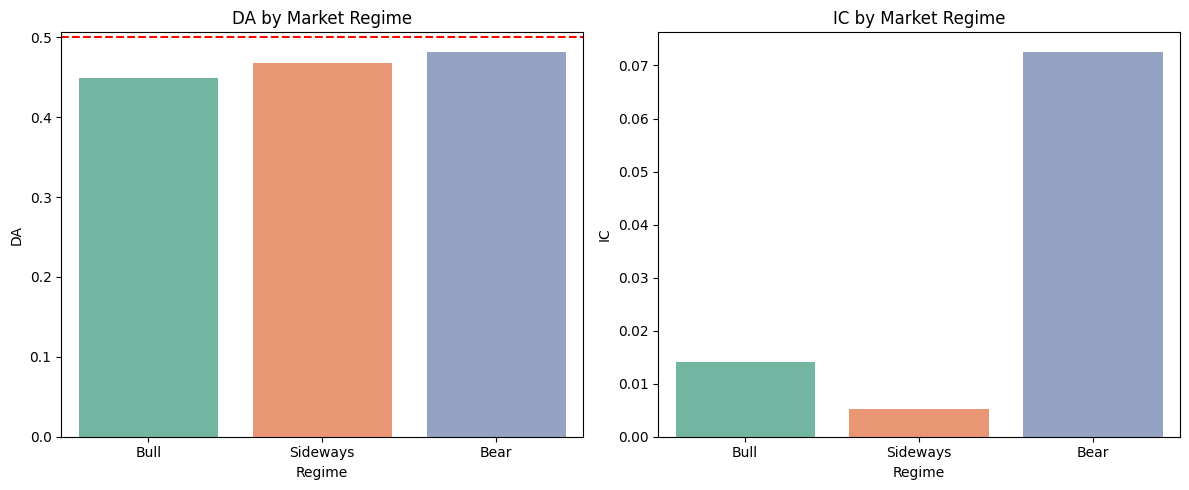

In [37]:
# Tính toán metric theo từng regime để vẽ biểu đồ
regime_metrics = []
for regime in ["Bull", "Sideways", "Bear"]:
    mask = results["regime_hmm"] == regime
    if mask.sum() > 0:
        m = eval_metrics(results.loc[mask, "target"].values, results.loc[mask, "pred"].values)
        m['Regime'] = regime
        regime_metrics.append(m)

df_regime = pd.DataFrame(regime_metrics)

plt.figure(figsize=(12, 5))

# Vẽ DA và IC theo Regime
plt.subplot(1, 2, 1)
sns.barplot(data=df_regime, x='Regime', y='DA', palette='Set2')
plt.axhline(0.5, color='red', linestyle='--')
plt.title('DA by Market Regime')

plt.subplot(1, 2, 2)
sns.barplot(data=df_regime, x='Regime', y='IC', palette='Set2')
plt.title('IC by Market Regime')

plt.tight_layout()
plt.show()

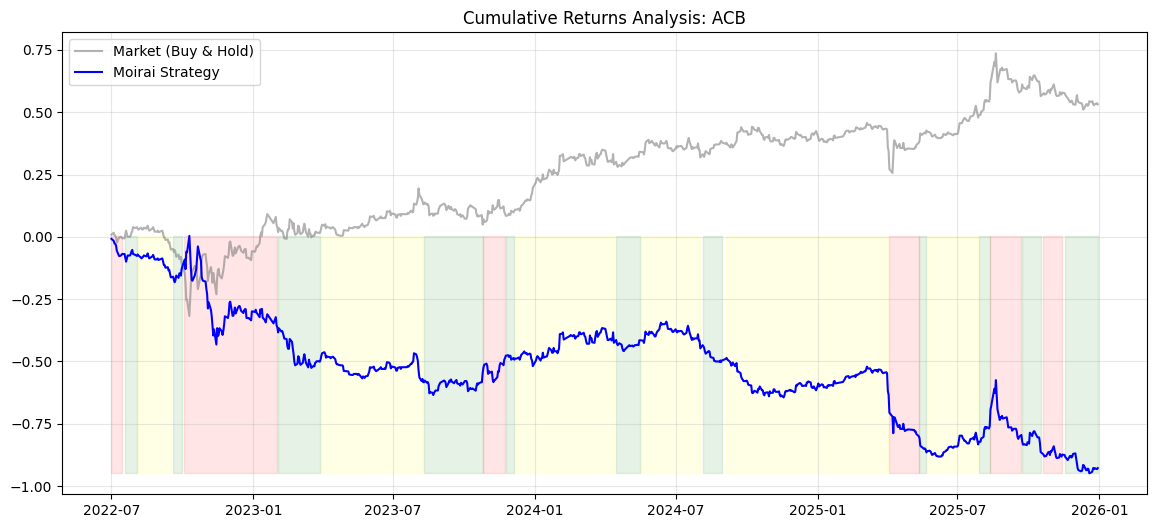

In [38]:
# Chọn 1 ticker tiêu biểu hoặc tính trung bình toàn bộ
ticker_to_plot = tickers[0] # Ví dụ: ACB
df_ticker_res = results[results['ticker'] == ticker_to_plot].sort_values('Date')

# Tính lợi nhuận cộng dồn (Simple Strategy: Sign of Prediction)
df_ticker_res['strategy_returns'] = np.sign(df_ticker_res['pred']) * df_ticker_res['target']
df_ticker_res['cum_market'] = df_ticker_res['target'].cumsum()
df_ticker_res['cum_strategy'] = df_ticker_res['strategy_returns'].cumsum()

plt.figure(figsize=(14, 6))
plt.plot(df_ticker_res['Date'], df_ticker_res['cum_market'], label='Market (Buy & Hold)', color='gray', alpha=0.6)
plt.plot(df_ticker_res['Date'], df_ticker_res['cum_strategy'], label='Moirai Strategy', color='blue')

# Vẽ vùng background cho Regime
unique_regimes = df_ticker_res['regime_hmm'].unique()
colors = {'Bull': 'green', 'Sideways': 'yellow', 'Bear': 'red'}
for regime in unique_regimes:
    mask = df_ticker_res['regime_hmm'] == regime
    plt.fill_between(df_ticker_res['Date'], df_ticker_res['cum_strategy'].min(), df_ticker_res['cum_strategy'].max(), 
                     where=mask, color=colors.get(regime, 'white'), alpha=0.1)

plt.title(f'Cumulative Returns Analysis: {ticker_to_plot}')
plt.legend()
plt.grid(alpha=0.3)
plt.show()

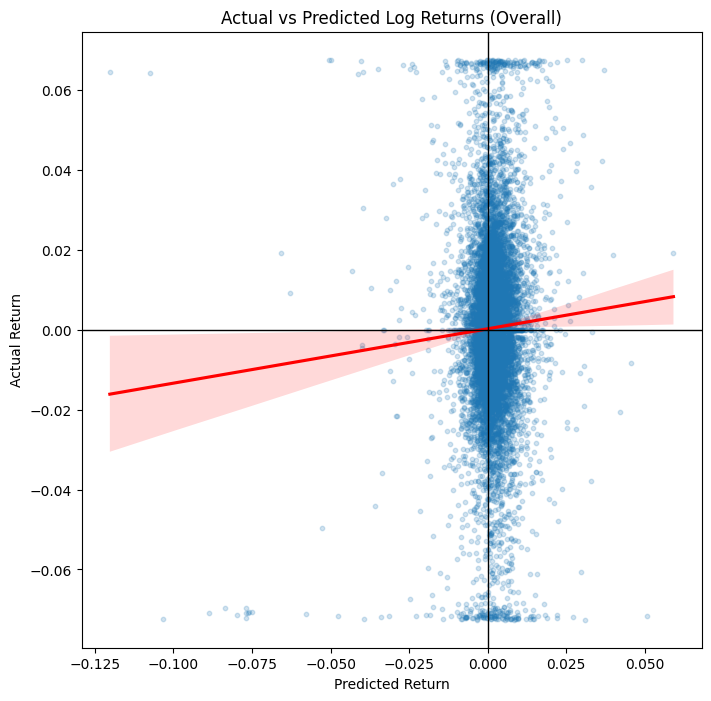

In [39]:
plt.figure(figsize=(8, 8))
sns.regplot(data=results, x='pred', y='target', 
            scatter_kws={'alpha':0.2, 's':10}, 
            line_kws={'color':'red'})
plt.axhline(0, color='black', lw=1)
plt.axvline(0, color='black', lw=1)
plt.title('Actual vs Predicted Log Returns (Overall)')
plt.xlabel('Predicted Return')
plt.ylabel('Actual Return')
plt.show()

In [40]:
print("Số rows pred=0:", (results["pred"] == 0.0).sum())
print("Ngày đầu tiên pred != 0:")
print(results[results["pred"] != 0.0].groupby("ticker")["Date"].min())

Số rows pred=0: 0
Ngày đầu tiên pred != 0:
ticker
ACB   2022-07-01
BVH   2022-07-01
CTG   2022-07-01
FPT   2022-07-01
GAS   2022-07-01
HPG   2022-07-01
KDH   2022-07-01
MBB   2022-07-01
MSN   2022-07-01
PDR   2022-07-01
SSI   2022-07-01
STB   2022-07-01
VCB   2022-07-01
VIC   2022-07-01
VNM   2022-07-01
Name: Date, dtype: datetime64[ns]
